In [526]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

TRIVIA_QA_PATH = os.getenv('TRIVIA_QA_PATH')
Natural_Questions_PATH = os.getenv('Natural_Questions_PATH')
SQUAD_PATH = os.getenv('SQUAD_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [3]:
from knowledge_maze.create_dataset.load_datasets import load_data
load_data(f"{REPO_PATH}\data_files\extracted_data.json")

Processing SQuAD: 100%|████████████████████████████████████████████████████████████| 442/442 [00:00<00:00, 1002.85it/s]


Loaded 272007 question-answer pairs in total.


In [1004]:
# Load from saved dataset:
extracted_data = load_json(f"{REPO_PATH}\data_files\extracted_data.json")

# 2. Data preprocess:
- Filter out problematic questions (long answers, answers within questions, complex questions)
- Classify answers by types of entities anf filter out irrelevant types
- Update entity types in the dataset

Filtering WH questions: 100%|██████████████████████████████████████████████| 272007/272007 [00:00<00:00, 421352.15it/s]


244638 out of 272007 samples have passed (89.9%).


Filtering self containing questions: 100%|█████████████████████████████████| 244638/244638 [00:02<00:00, 102244.55it/s]


242584 out of 244638 samples have passed (99.2%).


Filtering out long questions: 100%|███████████████████████████████████████| 242584/242584 [00:00<00:00, 1569093.82it/s]


...

9038 numerical samples found (4.0%).


Extracting date & time samples: 100%|██████████████████████████████████████| 226408/226408 [00:00<00:00, 508950.34it/s]


22159 date & time samples found (9.8%).


Extracting rest of the relevant samples: 100%|████████████████████████████| 226408/226408 [00:00<00:00, 2635084.87it/s]


88559 relevant samples found (39.1%).
Generating pie chart for 8 types...


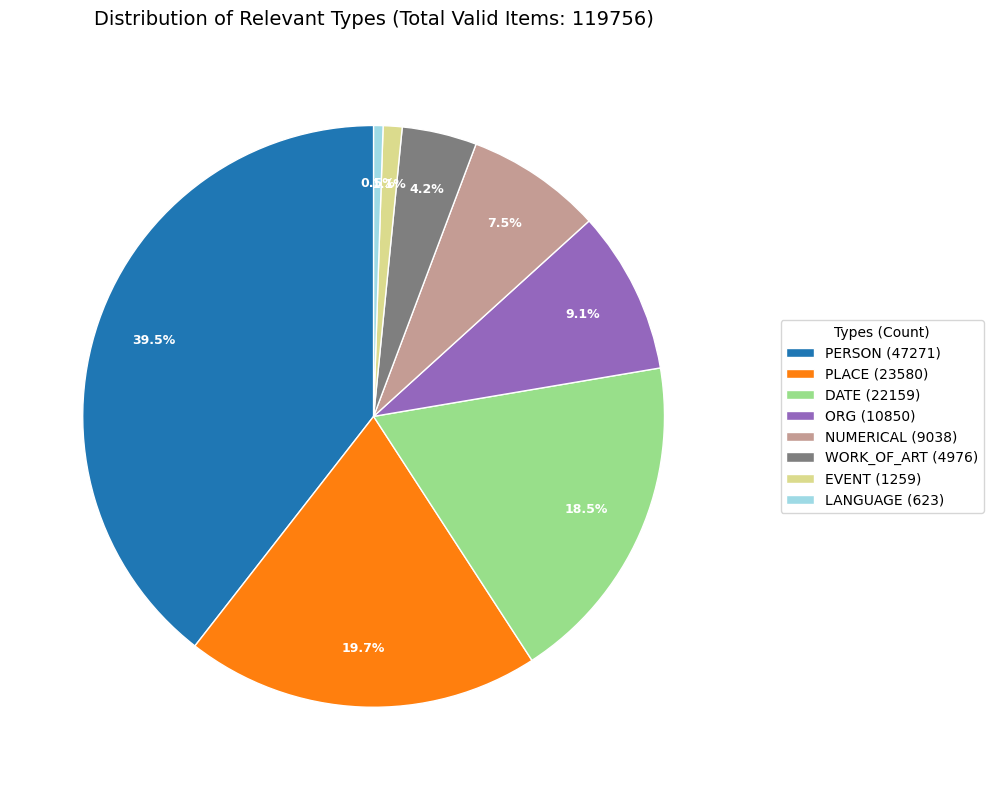

In [1101]:
from knowledge_maze.create_dataset.preprocess import preprocess
processed_data = preprocess(extracted_data, output_path=f"{REPO_PATH}\data_files\processed_data.json")

In [442]:
# Load from saved dataset:
processed_data = load_json(f"{REPO_PATH}\data_files\processed_data.json")

# 3. Group questions:
- Group Questions togather based on shared answers
- Questions with numerical and date answers are grouped by closed value answers instead of exact match
- Filter out questions that are too semantically similar
- Filter out ambiguous questions
- Create candidate reasoning chains for the dataset

Dividing data by type...
Creating reasoning paths for Date clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 11/11 [00:25<00:00,  2.29s/it]
Creating similarity graphs and filtering questions: 100%|█████████████████████████| 3095/3095 [00:06<00:00, 475.97it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 3095/3095 [00:00<00:00, 646547.01it/s]


Creating reasoning paths for Number clusters...


Generating question embeddings: 100%|████████████████████████████████████████████████████| 4/4 [00:11<00:00,  2.93s/it]
Creating similarity graphs and filtering questions: 100%|████████████████████████| 1056/1056 [00:01<00:00, 1051.78it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 1056/1056 [00:00<00:00, 374624.46it/s]


Creating reasoning paths for Place clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 12/12 [00:27<00:00,  2.33s/it]
Creating similarity graphs and filtering questions: 100%|█████████████████████████| 2162/2162 [00:02<00:00, 865.08it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 1736/1736 [00:00<00:00, 230903.52it/s]


Creating reasoning paths for General clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 15/15 [00:36<00:00,  2.41s/it]
Creating similarity graphs and filtering questions: 100%|████████████████████████| 4768/4768 [00:03<00:00, 1460.50it/s]
Splitting large clusters: 100%|███████████████████████████████████████████████| 4768/4768 [00:00<00:00, 1002277.43it/s]


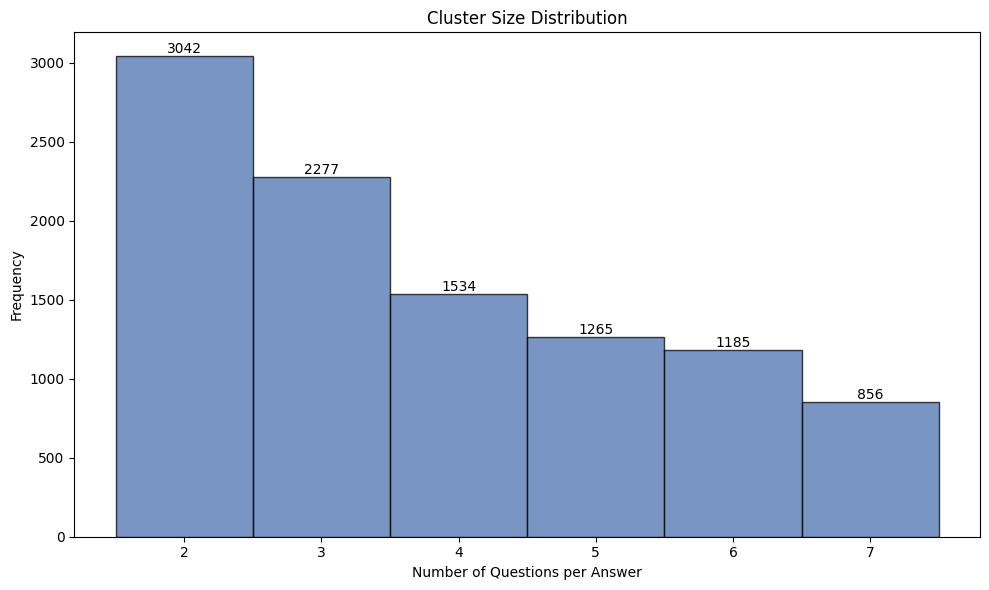

In [1346]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
cluster_data = await create_paths(processed_data, output_path=f"{REPO_PATH}\data_files\cluster_data.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.13s/it]

Answer: ('George Eliot', 'PERSON')
Questions before filtering:
1. Mary Anne Evans was the real name of which famous novelist?
2. What is the pen-name of novelist Mary Ann Evans (1819-80)?
3. English novelist Mary Anne Evans is better known by what name?


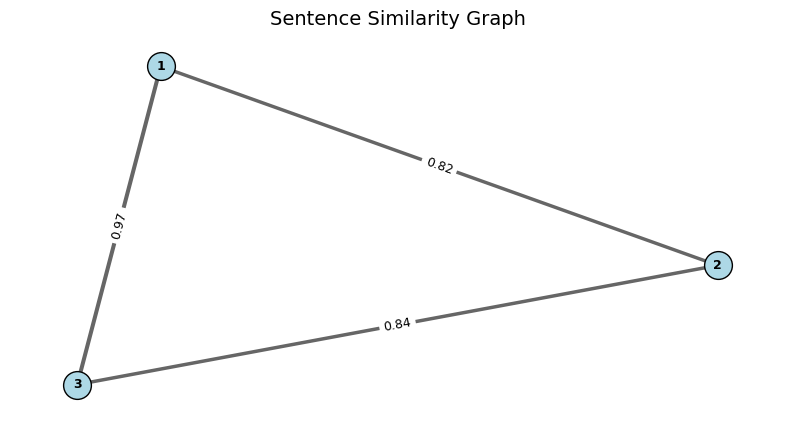

Questions after filtering:
1. English novelist Mary Anne Evans is better known by what name?


In [1142]:
# Plot graph example - (filtering process):
from knowledge_maze.create_dataset.create_reasoning_path import display_random_sample
display_random_sample(processed_data)

In [3]:
# Load from saved dataset:
cluster_data = load_json(f"{REPO_PATH}\data_files\cluster_data.json")

# 4. Create Structured Data:
- Split questions list into reasoning paths and extract main question
- Create counter-factual answers
- Assign paragraph ids for each question pair
- Make an organized data structure for later usage and display data samples efficiently

**Dataset QA Structure:**
```
{
    'ID': '',
    'Question': '',
    'Answers': {
        'Memory answer': '',
        'Counter answer 1': '',
        'Counter answer 2': '',
        'Distractor answer': ''
    },
    'Answer type': '',
    'Reasoning path 1':[
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        ...
    ],
    'Reasoning path 2':[
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        ...
    ]
    'Distractor paragraphs': []
}
```

Creating dataset QA samples: 100%|██████████████████████████████████████████████| 10159/10159 [00:30<00:00, 338.41it/s]


Generating counter answers for numerical data:


Usage cost: 0.0405$ (Estimated: 0.04$): 100%|██████████████████████████████████████| 1225/1225 [00:31<00:00, 38.54it/s]


Generating counter answers for general & place data:


Usage cost: 0.2754$ (Estimated: 0.28$): 100%|██████████████████████████████████████| 6394/6394 [02:36<00:00, 40.83it/s]


Generating counter answers for date data:


Usage cost: 0.0000$ (Estimated: 0.00$): 100%|██████████████████████████████████████| 2540/2540 [00:33<00:00, 75.23it/s]


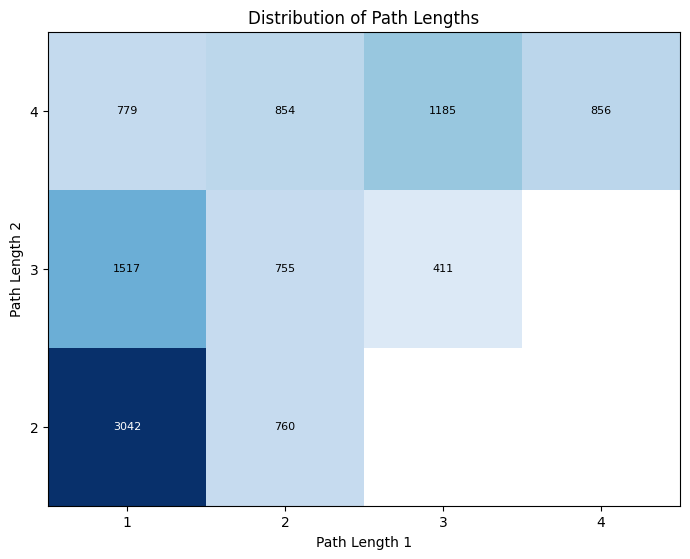

Aggregating question counts by type...
Generating stacked bar plot for 10159 samples...


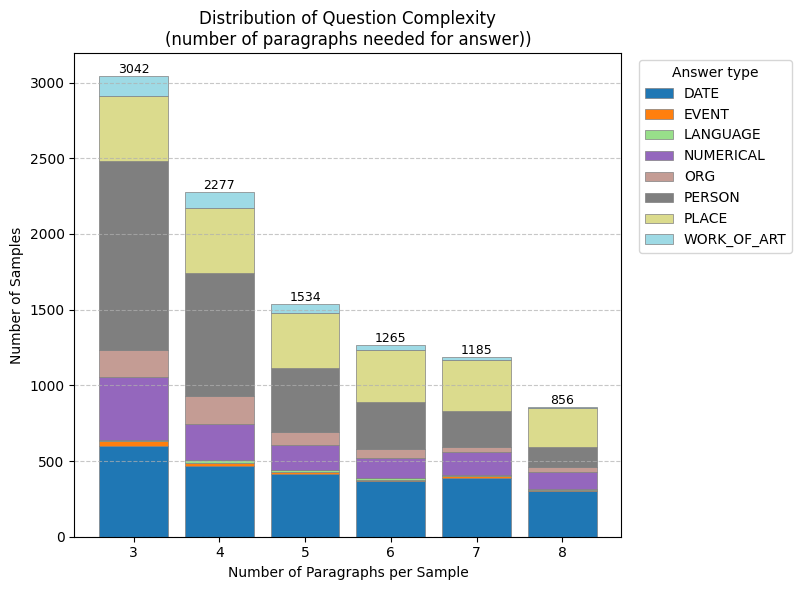

In [1347]:
from knowledge_maze.create_dataset.create_data_qa import create_data_qa
knowledge_maze_qa = await create_data_qa(cluster_data, output_path=f"{REPO_PATH}\data_files\knowledge_maze_qa.json")

In [1353]:
# Show random sample:
from knowledge_maze.create_dataset.create_data_qa import display_qa_sample
display_qa_sample(random.choice(knowledge_maze_qa))

ID: ae33804f-ebf4-4ebe-9772-98cac4522255
Question: Who does the US share water borders with in the northwest?
Answer (Original): Russia
Answer type: PLACE

Answers:
- Russia (Memory answer)
- China (Counter answer 1)
- India (Counter answer 2)
- Iran (Distractor answer)

Sub-questions path 1:
 1. Who does the US share water borders with in the northwest? (Russia)
 2. After Morsi removal, what country has Egypt improved relations with? (Russia)
 3. Which country convinced Syria to actually give up its chemical weapons? (Russia)

Sub-questions path 2:
 1. Who does the US share water borders with in the northwest? (Russia)
 2. Where did Nigeria launch its first satellite? (Russia)
 3. Policy in regard to what country was discussed at Eisenhower's first cabinet meeting? (Russia)
 4. Who was the partner in the Treaty of Kyakhta? (Russia)


In [685]:
# Load from saved dataset:
knowledge_maze_qa = load_json(f"{REPO_PATH}\data_files\knowledge_maze_qa.json")

# 5. Generate paragraphs:
- aa
- aa
- aa

In [877]:
knowledge_maze_qa_who = [sample for sample in knowledge_maze_qa if sample['Answer type'] == 'PERSON']

In [885]:
from knowledge_maze.create_dataset.create_paragraphs import create_paragraphs
knowledge_maze_paragraphs = await create_paragraphs(random.sample(knowledge_maze_qa_who, k=10), output_path=os.path.join(REPO_PATH, "data_files", "knowledge_maze_paragraphs.json"))

Processing 10 QA samples to extract paragraph info...
Generating 29 'Chain' paragraphs...


Usage cost: 0.0037$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 29/29 [00:04<00:00,  6.59it/s]


Generating 20 'Edge' paragraphs...


Usage cost: 0.0023$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 20/20 [00:04<00:00,  4.11it/s]

Combining generated paragraphs with IDs...
Saving paragraph data to C:\Users\Daniel\Desktop\KnowledgeMaze\data_files\knowledge_maze_paragraphs.json...


In [888]:
# Show random paragraph sample:
from knowledge_maze.create_dataset.create_paragraphs import display_paragraph
p_id = random.choice(list(knowledge_maze_paragraphs.keys()))
display_paragraph(p_id)

Paragraph type: Chain

Questions:
- which celebrities have the most followers on instagram
- who is the girl from we don't talk anymore

Shared answer: Selena Gomez

Paragraph text: One prominent figure in the world of social media boasts an immense following, making
her one of the most recognized personalities on platforms like Instagram. This individual has captivated audiences
with her engaging content, leading to a staggering number of followers. In contrast, another notable figure, a
talented singer, gained significant recognition through her collaboration on a hit song, which highlights themes of
love and heartbreak. This song not only showcased her vocal prowess but also contributed to her rising popularity
in the music industry, further establishing her presence alongside other influential celebrities in contemporary
culture.


In [889]:
# Sanity check - see that the original answer does not appear in the paragraphs & the final counter-answers appear in the end:
from knowledge_maze.create_dataset.create_paragraphs import paragraph_preview_test
paragraph_preview_test()

Analyzing paragraphs and samples for answer containment...


Analyzing Samples: 100%|█████████████████████████████████████████████████████| 12254/12254 [00:00<00:00, 347918.80it/s]

⚠️ Missing PARAGRAPH_DATASET entry for ID 'cad58585-642b-4dc3-b581-e1f70d71febe' in sample 0. Skipping paragraph.
⚠️ Missing PARAGRAPH_DATASET entry for ID 'ac411495-aeb8-4715-834c-e6d6c3c5bed9' in sample 0. Skipping paragraph.
⚠️ Missing PARAGRAPH_DATASET entry for ID '822add49-450a-4877-a98d-9eadacd9c173' in sample 0. Skipping paragraph.
⚠️ Missing PARAGRAPH_DATASET entry for ID 'f01ed072-4d15-4f97-ba12-283fad9620cd' in sample 0. Skipping paragraph.
⚠️ Missing PARAGRAPH_DATASET entry for ID 'b3fd2484-d9f0-4de6-a838-46a90f9f4bf9' in sample 0. Skipping paragraph.
⚠️ Missing PARAGRAPH_DATASET entry for ID '4d9863d6-117d-49f5-bd9a-7104b9baf633' in sample 0. Skipping paragraph.
⚠️ Missing PARAGRAPH_DATASET entry for ID '6a3e41c3-78b2-4ac4-aad5-33d9e7f007f2' in sample 0. Skipping paragraph.
⚠️ Missing PARAGRAPH_DATASET entry for ID '6ec9fb4d-2779-4b8f-8d19-00394884080e' in sample 0. Skipping paragraph.
⚠️ Missing PARAGRAPH_DATASET entry for ID '2c43686f-8e7f-4da0-932f-80f5cdfc7a5e' in samp

Using tokenizer: cl100k_base
Calculating total paragraph tokens per QA sample...


Processing Samples: 100%|████████████████████████████████████████████████████| 12254/12254 [00:00<00:00, 221484.38it/s]

⚠️ Paragraph ID 'ac411495-aeb8-4715-834c-e6d6c3c5bed9' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '6a3e41c3-78b2-4ac4-aad5-33d9e7f007f2' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '6ec9fb4d-2779-4b8f-8d19-00394884080e' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '4d9863d6-117d-49f5-bd9a-7104b9baf633' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID 'b3fd2484-d9f0-4de6-a838-46a90f9f4bf9' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '822add49-450a-4877-a98d-9eadacd9c173' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID 'cad58585-642b-4dc3-b581-e1f70d71febe' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID 'f01ed072-4d15-4f97-ba12-283fad9620cd' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '1fcc77b4-68c5-425a-b833-ff6880f37bed' found in reasoning path but not in PARAGRAPH_DATASET.
⚠️ Paragraph ID '28

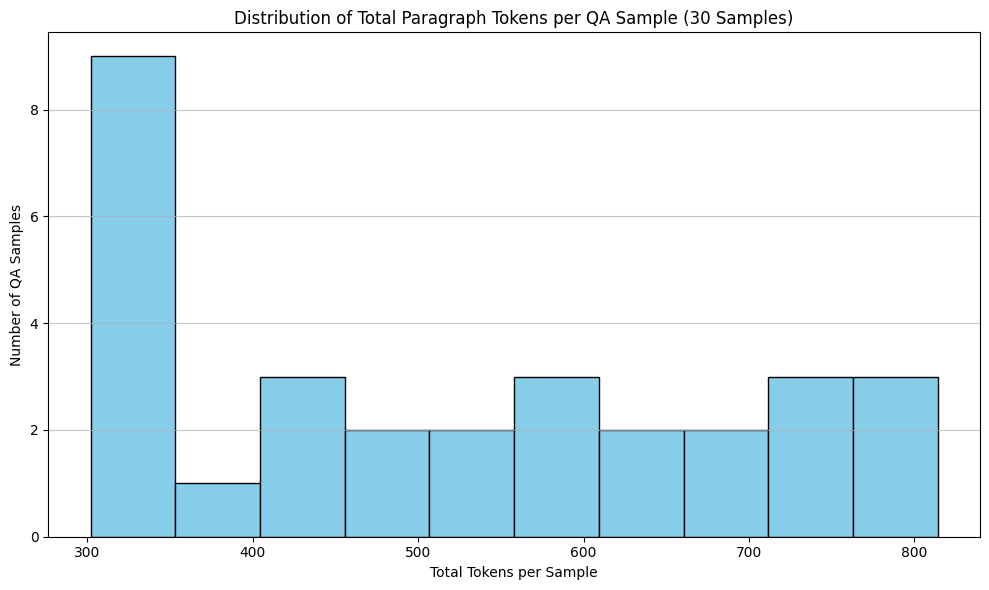

In [850]:
# Plot the number of tokens per data sample:
from knowledge_maze.create_dataset.create_paragraphs import plot_hist_token_size_per_sample
plot_hist_token_size_per_sample()

In [686]:
# Load from saved dataset:
knowledge_maze_paragraphs = load_json(f"{REPO_PATH}\data_files\knowledge_maze_paragraphs.json")

### TODOS - Generate Paragraph Approaches:
(By order of implementation)
- **In paragraph creation need to think of a way to make it case sensitive, or make a prompt with reasoning process... (CoT)**
- Adverserial to itself - ask the model again to rephrase failed paragraphs with explicitly deleting the answer.
- 2 step - tell me a story about the answer to the two question, after that take the output and remove him from the paragraph.
- with high temprature - generate X option, and than another model need to choose the best one.
- DSPy?? with 10-20 samples.

### Notes about the q-a samples creation process:
- In places 
- Still some temporal date questions.

# 6. Add distractor paragraphs:
- ..
- ..
- ..

### How to make Questions better matches?
**most of the fixes will be either in the clustering method or in the filer ambiguity parts.**
1.  ~~People - Remove anything that is not a full name (e.g. only one word) - it is ambiguous.~~
2.  ~~Places and Organizations (ORG, LOC, GPE, FAC) - give a model to classify if the answer is ambiguous or not.~~
3.  ~~Dates - probably semntic - Make dates larger clusters and than cluster like numbers. Also rephrase questions to ask exactly the answer type (instead of ambiguity) (need to think)~~
4.  ~~Numerical - use LLM to show what is being asked about and cluster by that.~~
5.  ~~Work of art, Events, Language - stay as is (maybe delete depends on the neccessaty)~~
6.  ~~Product, LAW, NORP - remove from data~~
7.  ~~If a question has more than one entity in the answer I want to remove it… need to see what happened in my filtering process. - looks like no option to solve~~
8.	~~Maybe filter out more aggressivly the ambiguous questions (and answers...), and delete questions where the answers are too obvious - like who won the us-meixco war etc.~~
9.  Dates - maybe like numericals, or with respect to location? or just start with embedding clustering and than make it by format and proximity.
10. Numbers - maybe cluster by a more general objectives? or even just like the dates - objective, location and agent.

# Tests:

In [ ]:
# TODO: Delete maybe?
async def extract_metadata(dataset: list[dict]) -> list[dict]:
    """..."""
    # Create LLM API call objects:
    metadata_extractor = gptAPI(METADATA_PROMPT,
                                output_format='list',
                                temperature=0.2,
                                max_concurrent_requests=100,
                                max_rpm=4900)

    # Extract inputs:
    inputs = [f"Q: {sample['Question']}\nA: {sample['Answer']}\n→" for sample in dataset]

    # Run the classification to extract objectives from the questions:
    metadata = await metadata_extractor.async_run(inputs)

    # Create a copy of clusters to filter out ambiguous questions:
    output_data = dataset.copy()
    for sample, meta in zip(output_data, metadata):
        sample['Metadata'] = meta

    return output_data

In [1270]:
knowledge_maze_qa_cardinal = [sample for sample in knowledge_maze_qa if sample['Answer type'] in ['NUMERICAL']]

In [1159]:
from knowledge_maze.create_dataset.create_data_qa import get_questions

cardinal_questions = [[f"Question: {question}, Answer: {sample['Answer']}" for question in get_questions(sample)] for sample in knowledge_maze_qa_cardinal]
cardinal_questions_flat = [item for sublist in cardinal_questions for item in sublist]

In [1200]:
from knowledge_maze.tools.api_tools import *

PROMPT = """You will be given a question (and optionally its answer) about an event that occurred at a specific time. Your task is to extract three key pieces of structured information:

- event_type: What kind of event is being asked about? (e.g., movie release, election, birth, product launch, etc.)
- location: The country or continent where the event happened. Use "Global" if it was a global event, and "None" if the location is unknown or not mentioned.
- agent: The person, group, or organization responsible for or directly involved in the event. Use "None" if not applicable.

Return the result as a Python-style list:  
[event_type, location, agent]

Examples:

Q: When did NASA launch Voyager 1?  
A: September 5, 1977  
→ ["space launch", "USA", "NASA"]

Q: When was Barack Obama born?  
A: August 4, 1961  
→ ["birth", "USA", "Barack Obama"]

Q: When did the Berlin Wall fall?  
A: November 9, 1989  
→ ["historical event", "Germany", "None"]

Q: What year was Titanic released?  
A: 1997  
→ ["movie release", "None", "None"]

Q: When did Apple release the first iPhone?  
A: 2007  
→ ["product launch", "USA", "Apple"]

Q: When were the London Olympics held?  
A: 2012  
→ ["sporting event", "UK", "None"]

Q: When did Nelson Mandela become president?  
A: 1994  
→ ["political election", "South Africa", "Nelson Mandela"]

Q: When did the COVID-19 pandemic start?  
A: 2019  
→ ["pandemic outbreak", "Global", "None"]

Now extract the list for the following:"""

# Create LLM API call objects:
generator = gptAPI(PROMPT,
                   output_format='list',
                   temperature = 0.0,
                   max_concurrent_requests = 100,
                   max_rpm=4900)

what_is_asked = await generator.async_run(cardinal_questions_flat[:300])

Usage cost: 0.0247$ (Estimated: 0.02$): 100%|████████████████████████████████████████| 300/300 [00:12<00:00, 24.99it/s]


In [1317]:
from knowledge_maze.create_dataset.clustering_tools.cluster_questions import get_date_category
date_proc_data = [sample for sample in processed_data if  isinstance(sample['Type'], tuple)] #sample['Type'] == 'NUMERICAL']#
metadataset = await get_date_category(date_proc_data[:1000])

Usage cost: 0.0484$ (Estimated: 0.05$): 100%|██████████████████████████████████████| 1000/1000 [00:26<00:00, 38.13it/s]


In [1253]:
metadataset

[{'Question': "When did the founder of Jehovah's Witnesses say the world would end?",
  'Answer': {'Original': '1914', 'Normalized': '1914'},
  'Type': ('DATE', 'year'),
  'Metadata': ['apocalyptic prediction', 'Charles Taze Russell', 'None']},
 {'Question': 'What day of the week was the Wall Street Crash?',
  'Answer': {'Original': 'Thursday', 'Normalized': 'Thursday'},
  'Type': ('DATE', 'generic_day'),
  'Metadata': ['day of the week', 'None', 'None']},
 {'Question': 'In what year were US ground troops first dispatched to Vietnam?',
  'Answer': {'Original': '1965', 'Normalized': '1965'},
  'Type': ('DATE', 'year'),
  'Metadata': ['military deployment year', 'USA', 'Vietnam']},
 {'Question': 'In what year were women first admitted to Harvard?',
  'Answer': {'Original': '1969', 'Normalized': '1969'},
  'Type': ('DATE', 'year'),
  'Metadata': ['university admission year', 'Harvard University', 'USA']},
 {'Question': 'When was the Scrabble World championship first held?',
  'Answer': {'

In [1314]:
[f"{sample['Question']} --> {sample['Answer']}" for sample in metadataset if sample['Category'] == 'Olympics']

["When did London first host an Olympic Games? --> {'Original': '1908', 'Normalized': '1908'}",
 "Before 2012 when was the most recent time the Summer Olympics were held in London, UK? --> {'Original': '1948', 'Normalized': '1948'}",
 "As at 2014, when will the next Winter Olympics be held? --> {'Original': '2018', 'Normalized': '2018'}",
 "when was the last time china had the olympics --> {'Original': '2008', 'Normalized': '2008'}"]

In [1318]:
what_is_about = [sample['Category'] for sample in metadataset]
print(len(what_is_about))
print(len(list(set(what_is_about))))
c_count = Counter(what_is_about)
print(len([value for value in c_count.values() if value >= 2]))
Counter(what_is_about)

1000
107
52


Counter({'historical': 229,
         'sports': 173,
         'entertainment': 113,
         'politics': 46,
         'music': 40,
         'film': 35,
         'gaming': 27,
         'television': 20,
         'technology': 20,
         'legal': 16,
         'business': 14,
         'literature': 14,
         'construction': 14,
         'birth date': 12,
         'military': 12,
         'holiday': 11,
         'currency': 11,
         'transportation': 10,
         'finance': 9,
         'automotive': 8,
         'aviation': 7,
         'space exploration': 7,
         'cultural': 7,
         'natural disaster': 7,
         'birth dates': 6,
         'religion': 5,
         'education': 5,
         'astronomy': 5,
         'invention': 4,
         'health policy': 4,
         'environmental': 4,
         'fashion': 4,
         'weather': 3,
         'gambling': 3,
         'birth year': 3,
         'toys': 3,
         'time change': 3,
         'film release': 3,
         'calendar':

In [1192]:
print(len(what_is_asked))
# print(len(set(what_is_asked)))

300


In [1205]:
cardinal_dict = {}
for what in list(what_is_asked):
    cardinal_dict[what[2]] = []
for ques, what in zip(cardinal_questions_flat[:300], what_is_asked):
    cardinal_dict[what[2]].append(ques)

In [1210]:
cardinal_dict['United States']

["Question: When did United States begin to provide foreign aid to Israel?, Answer: {'Memory answer': '1970', 'Counter answer 1': '1972', 'Counter answer 2': '1971', 'Distractor answer': '1975'}"]

In [1196]:
from collections import Counter
freqs = Counter(what_is_asked)

TypeError: unhashable type: 'list'

In [1181]:
count = 0
for freq in freqs.values():
    if freq >= 2:
        count += 1

print(count)

115


In [1182]:
freqs

Counter({'release date': 182,
         'movie release': 166,
         'season premiere': 75,
         'episode release': 54,
         'album release': 44,
         'show premiere': 37,
         'season release': 36,
         'song release': 34,
         'event date': 25,
         'episode airdate': 25,
         'TV show': 22,
         'game release': 19,
         'series premiere': 17,
         'TV show premiere': 15,
         'DVD release': 15,
         'book release': 13,
         'air date': 10,
         'publication date': 7,
         'filming date': 7,
         'season finale': 7,
         'episode date': 7,
         'season end': 6,
         'film release': 6,
         'show release': 6,
         'last episode': 6,
         'game date': 6,
         'election date': 5,
         'show return': 5,
         'premiere date': 5,
         'TV premiere': 5,
         'AFL season': 4,
         'term origin': 4,
         'tv show': 4,
         'show start': 4,
         'eruption date': 4,
 

In [1185]:
cardinal_dict['movie release']

["Question: In what month was the preview of Spectre released in movie theaters?, Answer: {'Memory answer': 'July', 'Counter answer 1': 'August', 'Counter answer 2': 'May', 'Distractor answer': 'June'}",
 "Question: when did once upon a time in venice come out, Answer: {'Memory answer': '11 August 2017', 'Counter answer 1': '21 August 2020', 'Counter answer 2': '26 January 2014', 'Distractor answer': '25 April 2016'}",
 "Question: when is the movie going in style coming out, Answer: {'Memory answer': '29 September 2017', 'Counter answer 1': '21 August 2021', 'Counter answer 2': '26 January 2018', 'Distractor answer': '25 April 2015'}",
 "Question: when does escape from mr. lemoncello's library movie come out, Answer: {'Memory answer': '9 October 2017', 'Counter answer 1': '21 August 2015', 'Counter answer 2': '26 January 2014', 'Distractor answer': '25 April 2018'}",
 "Question: when does the movie shot caller come out in theaters, Answer: {'Memory answer': '19 May 2017', 'Counter answ

dates:
- cluster all by similarity
- change questions to what year/month/century etc.

In [971]:
cluster_types = [sample['Answer type'] for sample in knowledge_maze_qa]
Counter(cluster_types)

Counter({'PERSON': 4297,
         'DATE': 2991,
         'GPE': 2081,
         'CARDINAL': 853,
         'ORG': 716,
         'WORK_OF_ART': 352,
         'LOC': 351,
         'NORP': 180,
         'FAC': 116,
         'EVENT': 96,
         'LANGUAGE': 69,
         'MONEY': 53,
         'PRODUCT': 44,
         'PERCENT': 33,
         'AGE': 13,
         'LAW': 9})

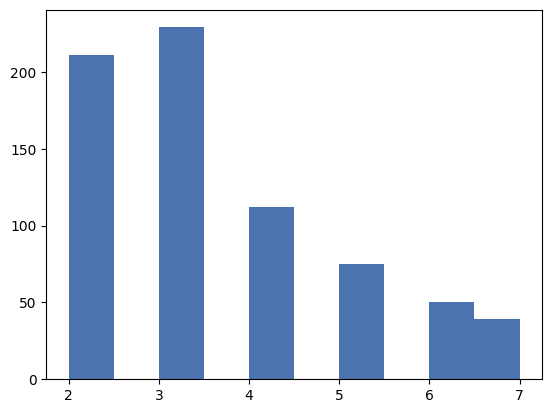

In [999]:
plt.hist([len(get_questions(sample)) for sample in knowledge_maze_qa if sample['Answer type'] == 'ORG'])
plt.show()

In [1094]:
[f"{sample['Question']} --> {sample['Answer']['Memory answer']}" for sample in knowledge_maze_qa if sample['Answer type'] == 'NORP']

['In 300 BC, the country now known as Spain was part of which empire? --> Roman',
 'Much medieval literature was influenced by the works of what classic culture? --> Roman',
 "What nationality was the inventor of the Rubik's Cube? --> Hungarian",
 'Of what nationality was Michel Aflaq? --> Syrian',
 'Which race of people made it the highest growing ethnicity between 2000-2010 in NYC? --> Asians',
 'Wiki, as in Wikipedia, is a word that means fast or quick - in what language? --> Hawaiian',
 'From what people did it appear the Etruscans had model their form of warfare on? --> Greeks',
 'In which North American style of football is the line of scrimmage never inside the one-yard line? --> Canadian',
 'What genre did Zane Grey write in? --> Western',
 "What is New Zealand's native population called? --> Māori",
 'What is the most commonly practiced religion in the Congo? --> Catholics',
 'What is Bostons largest religious group today? --> Catholics',
 'What group did France split Vietnam 

- people
- places
- items
- groups/organizations/nationalities
- numericals
- dates

In [1031]:
from knowledge_maze.tools.api_tools import *

PROMPT = """you get a question-answer pairs, give a category to the answer, choose from the following:
- person (full name)
- person (partial)
- places (names of places like cities, countries, buildings etc.)
- items (products, materials etc.)
- groups (companies, organizations, groups of people like teams etc.)
- nationalities
- numericals (pure numbers, age, money, percent. only definite numbers, not spans)
- work of art (painting, movie name etc.)
- dates
- others
"""

# Create LLM API call objects:
generator = gptAPI(PROMPT,
                   temperature = 0.2,
                   max_concurrent_requests = 100,
                   max_rpm=4900)

In [1042]:
cluster_data[0]

{'Answer': ('Tim Burton', 'PERSON'),
 'Questions': ['Who directed the 1988 film ‘Beetle Juice’?',
  'Who directed the 2001 remake of the film ‘Planet of the Apes’?',
  '"Who directed the 2003 film starring Ewan McGregor, Billy Crudup and Albert Finney called ""Big Fish""?"',
  '"Who directed ""The Nightmare Before Christmas"" and ""Edward Scissorhands""?"',
  "Who directed the 2010 fantasy film 'Alice In Wonderland', starring Mia Wasikowska and Johnny Depp amongst others?",
  "who did the art for don't starve",
  "Who directed 'Batman'?"]}

In [1055]:
pair_inputs = [[f"Question: {question}, Answer: {sample['Answer'][0]}" for question in sample['Questions']] for sample in cluster_data[:100]]
pair_inputs_flats = [item for sublist in pair_inputs for item in sublist]
verdict = await generator.async_run(pair_inputs_flats)

Usage cost: 0.0112$ (Estimated: 0.01$): 100%|████████████████████████████████████████| 365/365 [00:15<00:00, 23.23it/s]


In [1059]:
for sample, verd in zip(pair_inputs_flats, verdict):
    print(F"{sample} --> {verd}")

Question: Who directed the 1988 film ‘Beetle Juice’?, Answer: Tim Burton --> person (full name)
Question: Who directed the 2001 remake of the film ‘Planet of the Apes’?, Answer: Tim Burton --> person (full name)
Question: "Who directed the 2003 film starring Ewan McGregor, Billy Crudup and Albert Finney called ""Big Fish""?", Answer: Tim Burton --> person (full name)
Question: "Who directed ""The Nightmare Before Christmas"" and ""Edward Scissorhands""?", Answer: Tim Burton --> person (full name)
Question: Who directed the 2010 fantasy film 'Alice In Wonderland', starring Mia Wasikowska and Johnny Depp amongst others?, Answer: Tim Burton --> person (full name)
Question: who did the art for don't starve, Answer: Tim Burton --> person (partial)
Question: Who directed 'Batman'?, Answer: Tim Burton --> person (full name)
Question: Where was the site of the Hemudu and LIangzhu cultures?, Answer: Zhejiang --> places
Question: What was home to the warlord Yan Baihu?, Answer: Zhejiang --> plac

In [1057]:
list(set(verdict))

['person (full name)',
 'places',
 'person (partial)',
 'groups',
 'items',
 'nationalities',
 'work of art']

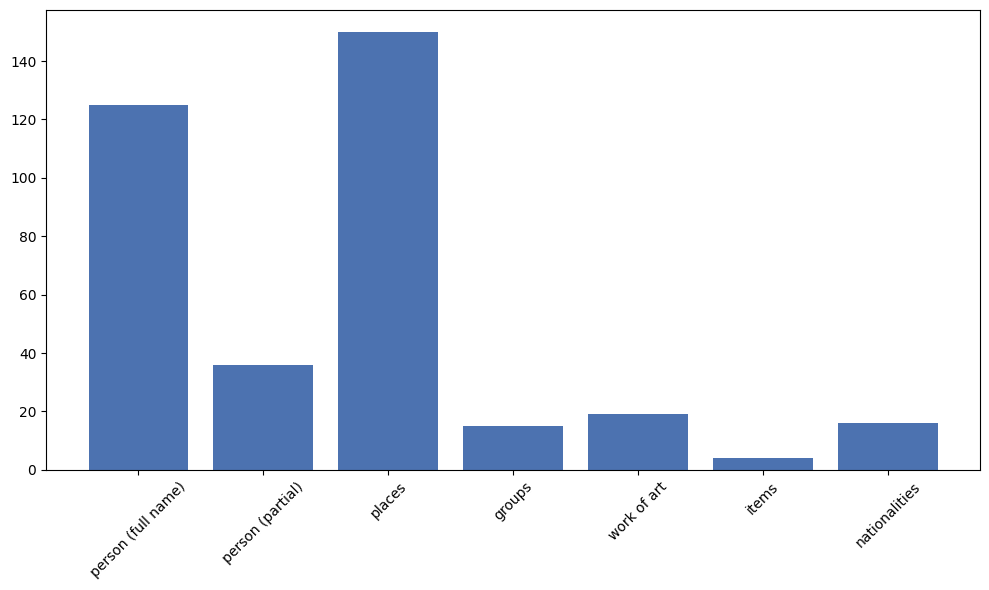

In [1058]:
from collections import Counter
import matplotlib.pyplot as plt

# Count the frequencies
counter = Counter(verdict)
labels, counts = zip(*counter.items())

# Plot
plt.figure(figsize=(10, 6))
plt.bar(labels, counts)  # Bar chart with exact labels
plt.xticks(rotation=45)  # Tilt x-axis labels
plt.tight_layout()
plt.show()

In [1096]:
person_answers = [sample['Answer']['Memory answer'] for sample in knowledge_maze_qa if sample['Answer type'] == 'PERSON']
count = 0
for ans in person_answers:
    if len(ans.split(' ')) < 2:
        count += 1
    else:
        print(ans)
print(f"{count} / {len(person_answers)}")

Tim Burton
Ricky Ponting
Paul Anka
Taron Egerton
Woody Guthrie
Charles Joel Nordström Kinnaman
Antonio Banderas
Jean - Baptiste Lamarck
Stephen F. Austin
Beth Tweddle
Tom Wolfe
Bernard Hill
P. D. James
Dan Quayle
Bob Monkhouse
Tom Cruise
Simon Mayo
Jennifer Lopez
Jennifer Lopez
Robert Redford
Charles Cornwallis
Barbara Cartland
Clint Walker
Henry Mancini
Robert Plant
Rokeby Venus
Adlai Stevenson
James Hutton
Wayne Fontana
Sandra Bullock
Lin - Manuel Miranda
Bill Pullman
Chadwick Aaron Boseman
Le Corbusier
Kelly Preston
Andy Devine
Bram Stoker
Sergei Prokofiev
Graham Norton
George II
William Jack Poulter
Boy George
Boy George
Fidel Castro
Jesse James
Chris Gayle
AnnaSophia Robb
Christopher Nolan
David Beckham
Graham Greene
Graham Greene
Iain Armitage
Carl Wilson
Dave Davies
Art Nouveau
Steven Hill
Ferdinand Magellan
William the Conqueror
Carl Jung
Delia Smith
Mary Celeste
Zinedine Zidane
Swoosie Kurtz
Henry Moore
Nicéphore Niépce
Franklin D. Roosevelt
Franklin D. Roosevelt
Franklin D. R

In [1086]:
from knowledge_maze.tools.api_tools import *

PROMPT = """return only true or false, if the following place, organization, location is definitive? can anyone understand the exact entity that is reffered to or is it ambiguous?
"""

# Create LLM API call objects:
generator = gptAPI(PROMPT,
                   output_format='bool',
                   temperature = 0.2,
                   max_concurrent_requests = 100,
                   max_rpm=4900)
input_ents = list(set([sample['Answer']['Memory answer'] for sample in knowledge_maze_qa if sample['Answer type'] in ['FAC']]))#['ORG', 'LOC', 'GPE']]))

In [1087]:
ambig_verdict = await generator.async_run(input_ents)

Usage cost: 0.0018$ (Estimated: 0.00$): 100%|████████████████████████████████████████| 115/115 [00:03<00:00, 35.82it/s]


In [1088]:
np.mean(ambig_verdict)

0.7739130434782608

In [1089]:
for ent, ver in zip(input_ents, ambig_verdict):
    print(f"{ent} --> {ver}")

Tower Bridge --> True
St. Pancras --> True
Covent Garden --> True
Newmarket --> False
Hampden Park --> True
Oval Office --> True
Angkor Wat --> True
Fenway Park --> True
Lord's Cricket Ground --> True
Charing Cross --> True
Sydney Harbour Bridge --> True
Coventry Cathedral --> True
Yankee Stadium --> True
Windsor Castle --> True
Wembley Stadium --> True
Riverside Drive --> False
Trevi Fountain --> True
Westminster --> False
Mercedes - Benz Stadium --> True
Vatican --> True
187th Street --> False
Parthenon --> True
Madison Square Garden --> True
Mornington Crescent --> False
Canterbury Cathedral --> True
Canal --> False
Tower of London --> True
Heathrow Airport --> True
Wembley Arena --> True
Wembley --> True
Flinders Street Station --> True
Dodger Stadium --> True
Westminster Bridge --> True
Piccadilly --> False
Berlin Wall --> True
Taj Mahal --> True
Balmoral Castle --> True
Bridge --> False
Louvre --> True
Disneyland --> True
Oxford --> True
Fleet Street --> True
Caledonian Canal -->